In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import matplotlib.pyplot as plt
import numpy as np

## Load data

In [3]:
import numpy as np
import pickle

tnobs = []

tn_datas_filepath = ["Data/converted_data_1string_BUG_g2.00_m5.00_2x2_dt0.010_Tmax12.00_exp_order30_M00064.txt", 
                     "Data/converted_data_1string_BUG_g0.01_m5.00_3x3_dt0.010_Tmax12.00_exp_order30_M00064.txt", 
                     "Data/converted_data_1string_BUG_g0.50_m0.30_3x3_dt0.010_Tmax12.00_exp_order30_M00064.txt"]

plot_times = [12, 12, 12]

for tfp in tn_datas_filepath:
    with open(tfp, "r") as f:
        tnobs.append(np.loadtxt(f))

## Auxiliary plot function

In [4]:
def plot_individual_tn_observables_ax(
    ax, 
    observable_matrix_tn, 
    qubit_indices, 
    x_ticks=None, 
    x_label=None,
    y_label=None, 
    y_lim=None,
    labels=None, 
    cmap=None, 
    title="", 
    legend=None,
):
    observable_matrix_tn = np.array(observable_matrix_tn)[:, qubit_indices]
    
    if labels is not None:
        if len(labels) != observable_matrix_tn.shape[1]:
            raise ValueError("labels must have the same length as number of observable")
    
    if cmap is None:
        cmap = plt.get_cmap("Set2")

    if x_ticks is not None:
        if len(x_ticks.shape) == 1:
            ax.set_xticks(x_ticks)
        else:
            ax.set_xticks(*x_ticks)
        x_tn = np.linspace(x_ticks[0], x_ticks[-1], observable_matrix_tn.shape[0])
    else:
        x_tn = np.arange(observable_matrix_tn.shape[0])

    if labels is None:
        labels = [f"$O_{i}$" for i in range(observable_matrix_tn.shape[1])]

    hlines = []
    for i in range(observable_matrix_tn.shape[1]):
        color = cmap((i % 8))
        ax.plot(x_tn, observable_matrix_tn[:, i], "-", markersize=10, markeredgecolor="black", color=color, label=labels[i], linewidth=4)
    
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label, labelpad=10)
    ax.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
    if y_lim == "data":
        min_data = np.nanmin(observable_matrix_tn)
        max_data = np.nanmax(observable_matrix_tn)
        ax.set_ylim([min_data - 0.05*(max_data - min_data), max_data + 0.05*(max_data - min_data)])
    elif y_lim is not None:
        ax.set_ylim(y_lim)
    if title:
        ax.set_title(title, pad=10, fontsize=26)
    if legend:
        ax.legend(handles=[ax.plot([], "o-", color=cmap(i % 8))[0] for i in range(observable_matrix_tn.shape[1])], labels=[line[0].get_label() if isinstance(line, list) else line.get_label() for line in hlines], loc="upper right", fontsize=16)

def plot_individual_tn_observables_ax_varlinewidth(
    ax, 
    observable_matrix_tn, 
    qubit_indices, 
    x_ticks=None, 
    x_label=None,
    y_label=None, 
    y_lim=None,
    labels=None, 
    cmap=None, 
    title="", 
    legend=None,
):
    observable_matrix_tn = np.array(observable_matrix_tn)[:, qubit_indices]
    
    if labels is not None:
        if len(labels) != observable_matrix_tn.shape[1]:
            raise ValueError("labels must have the same length as number of observable")
    
    if cmap is None:
        cmap = plt.get_cmap("Set2")

    if x_ticks is not None:
        if len(x_ticks.shape) == 1:
            ax.set_xticks(x_ticks)
        else:
            ax.set_xticks(*x_ticks)
        x_tn = np.linspace(x_ticks[0], x_ticks[-1], observable_matrix_tn.shape[0])
    else:
        x_tn = np.arange(observable_matrix_tn.shape[0])

    if labels is None:
        labels = [f"$O_{i}$" for i in range(observable_matrix_tn.shape[1])]

    hlines = []
    for i in range(observable_matrix_tn.shape[1]):
        color = cmap((i % 8))
        ax.plot(x_tn, observable_matrix_tn[:, i], "-", markersize=10, markeredgecolor="black", color=color, label=labels[i], linewidth=3 if i == 1 else 8)
    
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label, labelpad=10)
    ax.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
    if y_lim == "data":
        min_data = np.nanmin(observable_matrix_tn)
        max_data = np.nanmax(observable_matrix_tn)
        ax.set_ylim([min_data - 0.05*(max_data - min_data), max_data + 0.05*(max_data - min_data)])
    elif y_lim is not None:
        ax.set_ylim(y_lim)
    if title:
        ax.set_title(title, pad=10, fontsize=26)
    if legend:
        ax.legend(handles=[ax.plot([], "o-", color=cmap(i % 8))[0] for i in range(observable_matrix_tn.shape[1])], labels=[line[0].get_label() if isinstance(line, list) else line.get_label() for line in hlines], loc="upper right", fontsize=16)

def get_lims_from_ticks(ticks, relmargin, y_lim=None):
    if y_lim is not None:
        mask = np.logical_and(ticks >= y_lim[0], ticks <= y_lim[1])
        ticks = ticks[mask]
    min_tick = ticks[0]
    max_tick = ticks[-1]
    delta_ticks = max_tick - min_tick
    return [min_tick - relmargin * delta_ticks, max_tick + relmargin * delta_ticks]

## Data plots

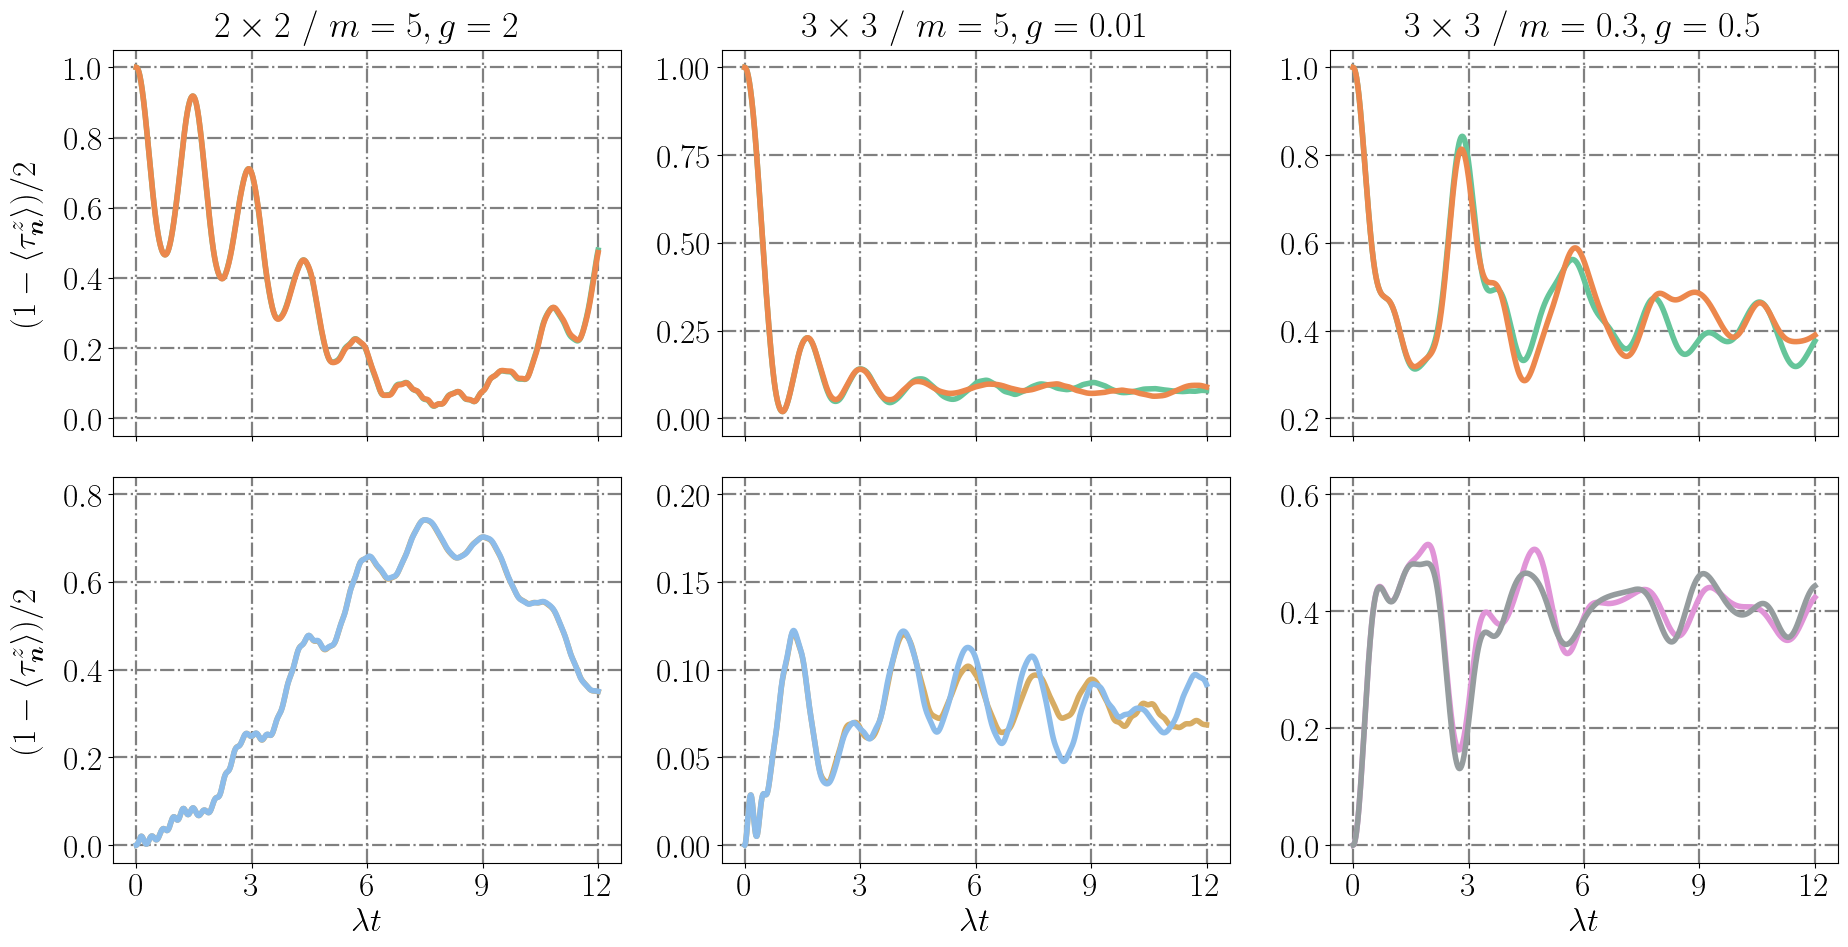

In [5]:
import matplotlib.pyplot as plt

# colors = ["#88B4DD", "#4E8988", "#56B389", "#8C8B5F", "#DC7C46", "#CD6B6E", "#CO7CB8", "#E1A132"]
colors = ["#8CBCEA", "#65C59A", "#e2d439", "#EC874C", "#EF8082", "#E094D7", "#D7AC63", "#AC9CF4", "#959C9E"]

row1_cmap = lambda x: [colors[1], colors[3]][x]
row2_cmap = lambda x: [colors[0], colors[-3]][::-1][x] #plt.get_cmap("Set2")(6 - 4*x)
row1_col3_cmap = lambda x: [colors[-4], colors[-1]][x] #lambda x: "darkkhaki" if x == 0 else "plum"
row2_col3_cmap = lambda x: [colors[4], colors[2]][x] #lambda x: "darkkhaki" if x == 0 else "plum"

plt.rc("text", usetex=True)
plt.rc("font", size=24, family="serif", weight="bold")
plt.rc("text.latex", preamble=r"\usepackage{amsmath}\usepackage{amssymb}\usepackage{bm}\usepackage{physics}")

fig, axs = plt.subplots(2, 3, figsize=(19, 10))

nxlabels = 5
margin = 0.05

# Col 1
qubit_indices00 = [4, 30]
x_ticks00 = np.linspace(0, plot_times[0], 6)
y_lim00 = [-0.05, 1]
title00 = r"$2 \times 2$ / $m = 5, g = 2$"
y_label00 = r"$(1 - \langle \tau_{\boldsymbol{n}}^z \rangle)/2$"
plot_individual_tn_observables_ax(axs[0, 0], 
                                    (1-tnobs[0])/2,
                                    qubit_indices=qubit_indices00,
                                    x_ticks=x_ticks00,
                                    x_label=None,
                                    y_label=r"$\langle n \rangle$",
                                    y_lim=y_lim00,
                                    cmap=row1_cmap,
                                    title=title00)
axs[0, 0].set_xticks(np.linspace(0, plot_times[0], nxlabels), [])
axs[0, 0].set_yticks(np.linspace(0, 1, 6))
axs[0, 0].set_ylabel(y_label00, labelpad=15)
axs[0, 0].set_ylim(get_lims_from_ticks(axs[0, 0].get_yticks(), margin, y_lim=y_lim00))

qubit_indices10 = [14, 20][::-1]
x_ticks10 = np.linspace(0, plot_times[0], 6)
y_lim10 = [-0.017, 0.8]
title10 = None
y_label10 = r"$(1 - \langle \tau_{\boldsymbol{n}}^z \rangle)/2$"
plot_individual_tn_observables_ax(axs[1, 0], 
                                    (1-tnobs[0])/2,
                                    qubit_indices=qubit_indices10,
                                    x_ticks=x_ticks10,
                                    x_label=None,
                                    y_label=r"$\langle n \rangle$",
                                    y_lim=y_lim10,
                                    cmap=row2_cmap,
                                    title=title10)
axs[1, 0].set_xticks(np.linspace(0, plot_times[0], nxlabels))
axs[1, 0].set_xlabel(r"$\lambda t$")
axs[1, 0].set_ylabel(y_label10, labelpad=15)
axs[1, 0].set_ylim(get_lims_from_ticks(axs[1, 0].get_yticks(), margin, y_lim=y_lim10))

# Col 2
qubit_indices01 = [4, 63]
x_ticks01 = np.linspace(0, plot_times[1], 6)
y_lim01 = [-0.05, 1.075]
title01 = r"$3 \times 3$ / $m = 5, g = 0.01$"
y_label01 = None
plot_individual_tn_observables_ax(axs[0, 1], 
                                    (1-tnobs[1])/2,
                                    qubit_indices=qubit_indices01,
                                    x_ticks=x_ticks01,
                                    x_label=None,
                                    y_label=y_label01,
                                    y_lim=y_lim01,
                                    cmap=row1_cmap,
                                    title=title01)
axs[0, 1].set_xticks(np.linspace(0, plot_times[1], nxlabels), [])
axs[0, 1].set_ylabel(y_label01, labelpad=15)
axs[0, 1].set_ylim(get_lims_from_ticks(axs[0, 1].get_yticks(), margin, y_lim=y_lim01))

qubit_indices11 = [8, 59][::-1] #[21, 48] #[21, 48]
x_ticks11 = np.linspace(0, plot_times[1], 6)
y_lim11 = [0, 0.2] #if col2_setting == "small" else None
title11 = None
y_label11 = None
plot_individual_tn_observables_ax(axs[1, 1], 
                                    (1-tnobs[1])/2,
                                    qubit_indices=qubit_indices11,
                                    x_ticks=x_ticks11,
                                    x_label=None,
                                    y_label=y_label11,
                                    y_lim=y_lim11,
                                    cmap=row2_cmap,
                                    title=title11)
axs[1, 1].set_xticks(np.linspace(0, plot_times[1], nxlabels))
axs[1, 1].set_xlabel(r"$\lambda t$")
axs[1, 1].set_ylabel(y_label11, labelpad=15)
axs[1, 1].set_ylim(get_lims_from_ticks(axs[1, 1].get_yticks(), margin, y_lim=y_lim11 if isinstance(y_lim11, list) else None))

# Col 3
qubit_indices02 = [4, 63]
x_ticks02 = np.linspace(0, plot_times[2], 6)
y_lim02 = [0.2, 1.025]
title02 = r"$3 \times 3$ / $m = 0.3, g = 0.5$"
y_label02 = None
plot_individual_tn_observables_ax(axs[0, 2], 
                                    (1-tnobs[2])/2,
                                    qubit_indices=qubit_indices02,
                                    x_ticks=x_ticks02,
                                    x_label=None,
                                    y_label=y_label02,
                                    y_lim=y_lim02,
                                    cmap=row1_cmap,
                                    title=title02)
axs[0, 2].set_xticks(np.linspace(0, plot_times[2], nxlabels), [])
axs[0, 2].set_ylabel(y_label02, labelpad=15)
axs[0, 2].set_ylim(get_lims_from_ticks(axs[0, 2].get_yticks(), margin, y_lim=y_lim02))

qubit_indices12 = [21, 48]
x_ticks12 = np.linspace(0, plot_times[2], 6)
y_lim12 = [-0.025, 0.7]
title12 = None
y_label12 = None
plot_individual_tn_observables_ax(axs[1, 2], 
                                  (1-tnobs[2])/2,
                                    # hobs[2], tnobs[2][:tn_data_limits[1], :],
                                    qubit_indices=qubit_indices12,
                                    # observable_confidence_hardware=hconfs[1],
                                    x_ticks=x_ticks12,
                                    x_label=None,
                                    y_label=y_label12,
                                    y_lim=y_lim12,
                                    cmap=row1_col3_cmap,
                                    title=title12)
axs[1, 2].set_xticks(np.linspace(0, plot_times[2], nxlabels))
axs[1, 2].set_xlabel(r"$\lambda t$")
axs[1, 2].set_ylabel(y_label12, labelpad=15)
axs[1, 2].set_ylim(get_lims_from_ticks(axs[1, 2].get_yticks(), margin, y_lim=y_lim12))

plt.tight_layout()
plt.savefig(f"data_tn_long_time_dynamics.svg", dpi=300)

## Legends

### Col 1

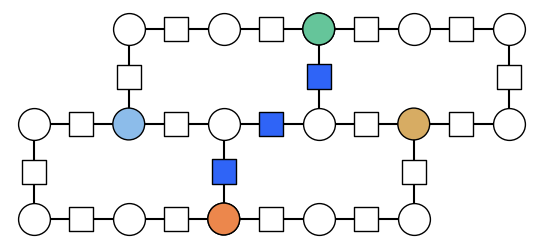

In [18]:
from z2hex.geometry import HeavyHexLattice

px, py = 2, 2
highlighted_qubits = qubit_indices00 + qubit_indices10

string_qubits = [4, 10, 17, 24, 30]

lattice = HeavyHexLattice(px, py)
lattice.plot_highlighted_qubits(string_qubits + highlighted_qubits, colors=["#2f64f7"]*len(string_qubits) + [row1_cmap(i % 8) for i in range(2)] + [row2_cmap(i % 8) for i in range(2)], number_highlighted=False, filepath="col1_legend.svg", number_qubits=False)

## Col 2

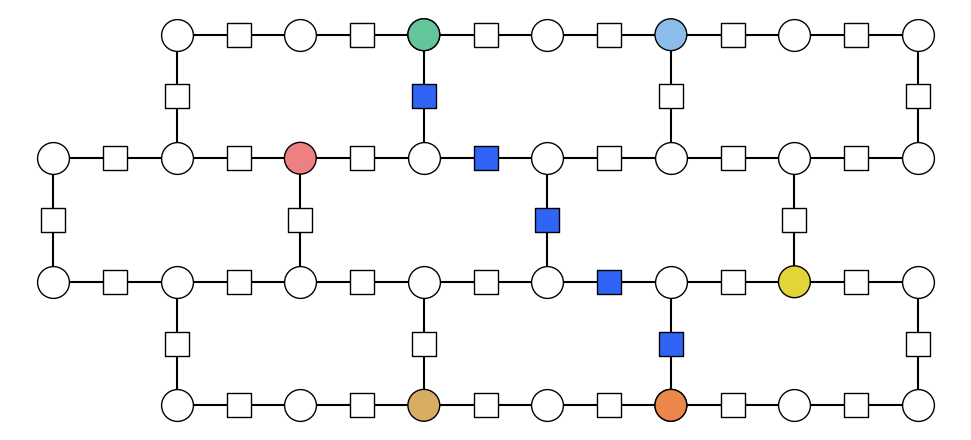

In [19]:
from z2hex.geometry import HeavyHexLattice

px, py = 3, 3
highlighted_qubits = qubit_indices01 + qubit_indices11 + qubit_indices12

string_qubits = [4, 14, 24, 34, 45, 53, 63]

lattice = HeavyHexLattice(px, py)
lattice.plot_highlighted_qubits(string_qubits + highlighted_qubits, colors=["#2f64f7"]*len(string_qubits) + [row1_cmap(i % 8) for i in range(2)] + [row2_cmap(i % 8) for i in range(2)] + [row2_col3_cmap(i) for i in range(2)], number_highlighted=False, filepath="col2_legend.svg")

## Col 3

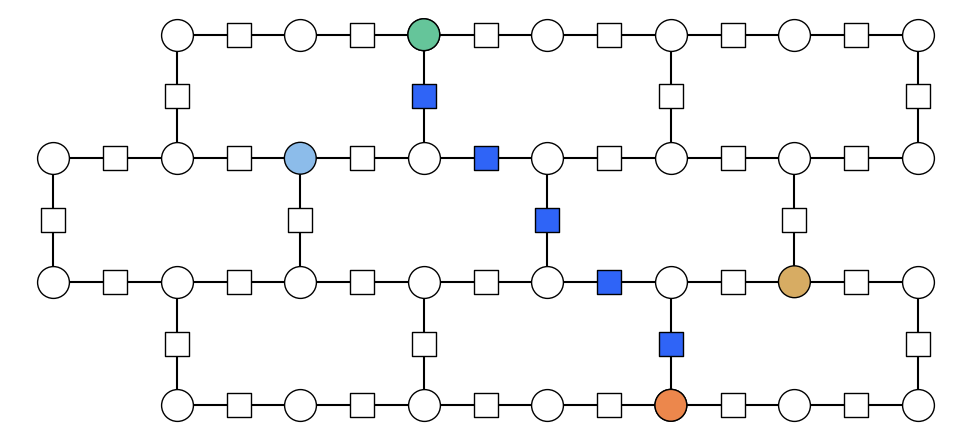

In [16]:
from z2hex.geometry import HeavyHexLattice

px, py = 3, 3
highlighted_qubits = qubit_indices02 + qubit_indices12

string_qubits = [4, 14, 24, 34, 45, 53, 63]

lattice = HeavyHexLattice(px, py)
lattice.plot_highlighted_qubits(string_qubits + highlighted_qubits, colors=["#2f64f7"]*len(string_qubits) + [row1_cmap(i % 8) for i in range(2)] + [row2_cmap(i % 8) for i in range(2)], number_highlighted=False, filepath="col3_legend.svg")